## Generates Fig. 4
The combined 3×5 confidence interval comparison figure (Monte Carlo simulation, Fisher information, profile likelihood) for both networks. Also computes the CI summary table.

In [1]:
import sys

import jax
import jax.numpy as jnp
import numpy as np

from cmfa.functions import calculate_ci, ordered_ilr_func

sys.path.insert(0, "../scripts")
import pickle
from functools import partial
from pathlib import Path

import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import tca_cycle
import toy_network
from jax import config
from matplotlib.lines import Line2D

config.update("jax_enable_x64", True)

import optimistix
import scipy.stats as stats

RESULTS_DIR_TOY = Path("..") / "data" / "results" / "toy_example"
RESULTS_DIR_TCA = Path("..") / "data" / "results" / "tca_cycle"
PLOT_DIR = Path("..") / "figures"

# ── palette ───────────────────────────────────────────────────────────────────
TRAD  = '#D27720'
ILR =  '#038C7F'
TRUE = '#1C0B9C'

# Random drawn index for the simulated MID used to calculate confidence intervals
IDX_TOY = 4699
IDX_TCA = 2484


### Toy network

In [2]:
# Toy network
true_flux_toy = np.load(RESULTS_DIR_TOY / "true_flux.npy")
simulated_mid_toy = jnp.load(RESULTS_DIR_TOY / "mid_simulated_reference.npy")

with open(RESULTS_DIR_TOY / "estimated_fluxes_reference.pkl", "rb") as f:
    estimated_fluxes_toy = pickle.load(f)

random_sim_toy = simulated_mid_toy[IDX_TOY]

sd_trad_toy = np.std(simulated_mid_toy, axis=0)
sd_ilr_toy = np.std(ordered_ilr_func(simulated_mid_toy), axis=0)

weights_trad_toy = 1/sd_trad_toy**2
weights_ilr_toy = 1/sd_ilr_toy**2

# Optimization with Optimistix
init_guess_toy = jnp.array([100.0, 50.0])
solver = optimistix.BFGS(rtol=1e-8, atol=1e-8)

opt_result_trad_toy = optimistix.minimise(
    toy_network.loss_trad,
    y0=jnp.log(init_guess_toy),
    args=(random_sim_toy, weights_trad_toy),
    solver=solver,
    max_steps=10000,
    throw=False,
    has_aux=True,
)

opt_result_ilr_toy = optimistix.minimise(
    toy_network.loss_ilr,
    y0=jnp.log(init_guess_toy),
    args=(random_sim_toy, weights_ilr_toy),
    solver=solver,
    max_steps=10000,
    throw=False,
    has_aux=True,
)

est_trad_toy = estimated_fluxes_toy["trad"][:, [4, 5]]
est_ilr_toy = estimated_fluxes_toy["ilr"][:, [4, 5]]

inv_hessian_trad_toy = opt_result_trad_toy.state.f_info.hessian_inv.pytree
standard_errors_trad_toy = jnp.sqrt(jnp.diag(inv_hessian_trad_toy))

inv_hessian_ilr_toy = opt_result_ilr_toy.state.f_info.hessian_inv.pytree
standard_errors_ilr_toy = jnp.sqrt(jnp.diag(inv_hessian_ilr_toy))


### TCA cycle

In [3]:
# tca cycle
true_flux_tca = np.load(RESULTS_DIR_TCA / "true_flux.npy", allow_pickle=True)
simulated_mid_tca = jnp.load(RESULTS_DIR_TCA / "mid_simulated_reference.pkl", allow_pickle=True)

with open(RESULTS_DIR_TCA / "estimated_fluxes_reference.pkl", "rb") as f:
    estimated_fluxes_tca = pickle.load(f)

random_sim_tca = jax.tree.map(lambda x: x[IDX_TCA], simulated_mid_tca)

sd_trad_tca = jax.tree.map(lambda x: np.std(x, axis=0), simulated_mid_tca)
sd_ilr_tca = jax.tree.map(lambda x: np.std(ordered_ilr_func(x), axis=0), simulated_mid_tca)

weights_trad_tca = jax.tree.map(lambda s: 1/s**2, sd_trad_tca)
weights_ilr_tca = jax.tree.map(lambda s: 1/s**2, sd_ilr_tca)

init_guess_tca = np.array([0.2, 0.2, 0.2])
solver = optimistix.BFGS(rtol=1e-8, atol=1e-8)

# Optimization with Optimistix
opt_result_trad_tca = optimistix.minimise(
    tca_cycle.loss_trad,
    y0=jnp.log(init_guess_tca),
    args=(random_sim_tca, weights_trad_tca),
    solver=solver,
    max_steps=10000,
    throw=False,
    has_aux=True,
)

opt_result_ilr_tca = optimistix.minimise(
    tca_cycle.loss_ilr,
    y0=jnp.log(init_guess_tca),
    args=(random_sim_tca, weights_ilr_tca),
    solver=solver,
    max_steps=10000,
    throw=False,
    has_aux=True,
)

est_trad_tca = estimated_fluxes_tca["trad"]
est_ilr_tca = estimated_fluxes_tca["ilr"]

inv_hessian_trad_tca = opt_result_trad_tca.state.f_info.hessian_inv.pytree
standard_errors_trad_tca = jnp.sqrt(jnp.diag(inv_hessian_trad_tca))

inv_hessian_ilr_tca = opt_result_ilr_tca.state.f_info.hessian_inv.pytree
standard_errors_ilr_tca = jnp.sqrt(jnp.diag(inv_hessian_ilr_tca))

### Monte Carlo confidence intervals

In [4]:
# Toy network
mc_toy_trad = np.array([[np.quantile(est_trad_toy[:, 0], 0.025), np.quantile(est_trad_toy[:, 0], 0.975)], 
                        [np.quantile(est_trad_toy[:, 1], 0.025), np.quantile(est_trad_toy[:, 1], 0.975)]])

mc_toy_ilr = np.array([[np.quantile(est_ilr_toy[:, 0], 0.025), np.quantile(est_ilr_toy[:, 0], 0.975)], 
                        [np.quantile(est_ilr_toy[:, 1], 0.025), np.quantile(est_ilr_toy[:, 1], 0.975)]])

# TCA cycle
mc_tca_trad = np.array([[np.quantile(est_trad_tca[:, 0], 0.025), np.quantile(est_trad_tca[:, 0], 0.975)], 
                        [np.quantile(est_trad_tca[:, 1], 0.025), np.quantile(est_trad_tca[:, 1], 0.975)],
                        [np.quantile(est_trad_tca[:, 2], 0.025), np.quantile(est_trad_tca[:, 2], 0.975)]])

mc_tca_ilr = np.array([[np.quantile(est_ilr_tca[:, 0], 0.025), np.quantile(est_ilr_tca[:, 0], 0.975)], 
                        [np.quantile(est_ilr_tca[:, 1], 0.025), np.quantile(est_ilr_tca[:, 1], 0.975)],
                        [np.quantile(est_ilr_tca[:, 2], 0.025), np.quantile(est_ilr_tca[:, 2], 0.975)]])

### Fisher information matrix confidence intervals

In [5]:
def get_sigma_v(N, inv_hessian, ix_input_flux):
    n_nofixed = jnp.delete(N, ix_input_flux, axis=1)
    return n_nofixed @ inv_hessian @ n_nofixed.T


def fisher_interval(log_flux_est, flux_sd):
    mu = log_flux_est
    sigma = flux_sd
    x_start = (mu - 3 * sigma)
    x_end = (mu + 3 * sigma)
    x_axis = np.linspace(x_start, x_end, 500)

    # Calculate Log-Normal PDF
    y_raw = stats.norm.pdf(x_axis, mu, sigma)

    return np.exp(x_axis), y_raw

#### Toy network

In [6]:
m_toy = jnp.array([[-1, -1, 2], [0, 0, -1], [-1, 0, 1]])
n_toy = jnp.vstack([-m_toy, jnp.eye(3)])
ix_input_flux_toy = np.array([0])

# Traditional I-MFA
sigma_v_trad = get_sigma_v(n_toy, inv_hessian_trad_toy, ix_input_flux_toy)
v3_trad, v5_trad = jnp.exp(opt_result_trad_toy.value)

v_free_trad = jnp.array([100, v3_trad, v5_trad])
# The fluxes calcualted from M and the free fluxes
v_full_trad = n_toy @ v_free_trad

flux_ci_toy_trad = calculate_ci(sigma_v_trad, jnp.log(v_full_trad))

# Compositional I-MFA
sigma_v_ilr = get_sigma_v(n_toy, inv_hessian_ilr_toy, ix_input_flux_toy)
v3_ilr, v5_ilr = jnp.exp(opt_result_ilr_toy.value)

v_free_ilr = jnp.array([100, v3_ilr, v5_ilr])
# The fluxes calcualted from M and the free fluxes
v_full_ilr = n_toy @ v_free_ilr

flux_ci_toy_ilr = calculate_ci(sigma_v_ilr, jnp.log(v_full_ilr))

#### TCA cycle

In [7]:
v_free_tca = {"v8": 0.215, "v1": 1, "v19": 0.05, "v20": 0.03, "v16": 0.07, "v17": 0.23, "v18": 0.12, "v2": 0.201, "v9": 0.296}
fixed_keys = ["v1", "v16", "v17", "v18", "v19", "v20"]
fixed_fluxes = {k: v_free_tca[k] for k in fixed_keys}

flux_from_free = partial(
    tca_cycle.flux_vector,
    fixed=fixed_fluxes,
)
n_tca = tca_cycle.get_N()
ix_input_flux_tca = np.array([1,2,3,4,5,6])

# Traditional I-MFA
flux_est_trad = flux_from_free(jnp.exp(opt_result_trad_tca.value))
sigma_v_tca_trad = get_sigma_v(n_tca, inv_hessian_trad_tca, ix_input_flux_tca)
flux_est_jax = jnp.array([flux_est_trad[k] for k in flux_est_trad.keys()])
flux_ci_tca_trad = calculate_ci(sigma_v_tca_trad, jnp.log(flux_est_jax))

# Compositional I-MFA
flux_est_ilr = flux_from_free(jnp.exp(opt_result_ilr_tca.value))
sigma_v_tca_ilr = get_sigma_v(n_tca, inv_hessian_ilr_tca, ix_input_flux_tca)
flux_est_jax_ilr = jnp.array([flux_est_ilr[k] for k in flux_est_ilr.keys()])
flux_ci_tca_ilr = calculate_ci(sigma_v_tca_ilr, jnp.log(flux_est_jax_ilr))

### Profile likelihood

In [8]:
with open(RESULTS_DIR_TOY / "profile_likelihood.pkl", "rb") as f:
    profile_toy = pickle.load(f)
with open(RESULTS_DIR_TCA / "profile_likelihood.pkl", "rb") as f:
    profile_tca = pickle.load(f)

# Toy network
profile_cis_toy_trad = profile_toy["trad"]["ci"]
profile_cis_toy_ilr = profile_toy["ilr"]["ci"]

# TCA cycle
profile_cis_tca_trad = profile_tca["trad"]["ci"]
profile_cis_tca_ilr = profile_tca["ilr"]["ci"]

### Combined comparison figure

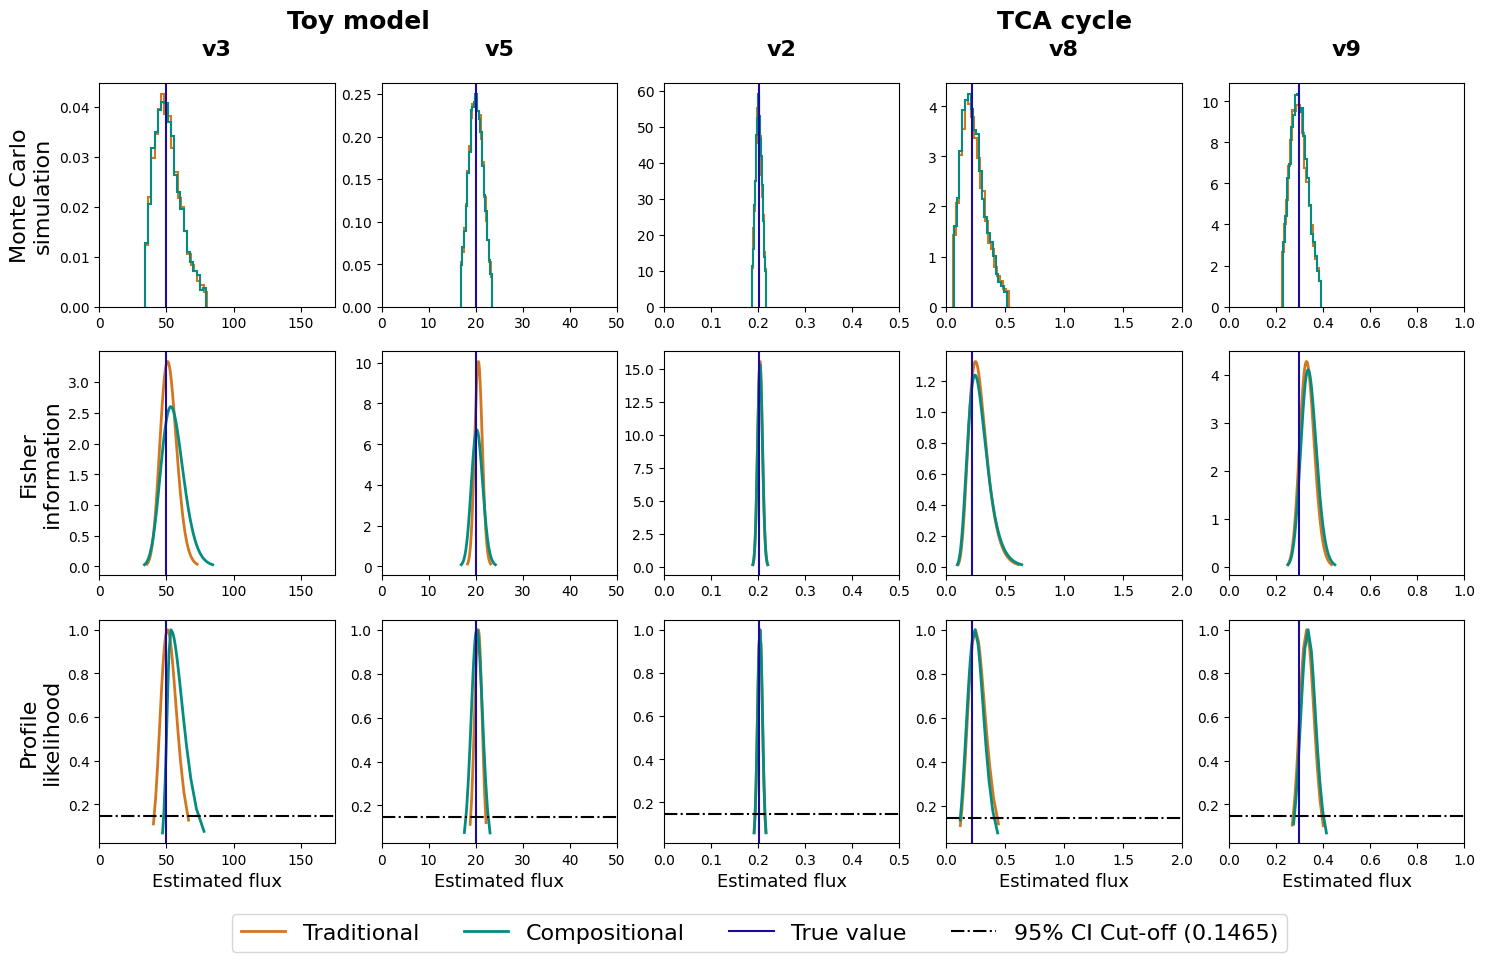

In [9]:
# Figure & Layout Setup: 3 rows (methods) x 5 columns (fluxes)
f3 = plt.figure(figsize=(15, 10))
gs3 = gridspec.GridSpec(3, 5, left=0.06, right=0.97, top=0.86, bottom=0.10, hspace=0.2, wspace=0.2)
axes3 = [[plt.subplot(gs3[r, c]) for c in range(5)] for r in range(3)]

# Per-column configuration: one entry per flux, shared across all 3 rows
col_configs = [
    {"idx": 0, "true_value": true_flux_toy[2], "opt_t": opt_result_trad_toy, "opt_i": opt_result_ilr_toy,
     "se_t": standard_errors_trad_toy, "se_i": standard_errors_ilr_toy,
     "est_t": est_trad_toy[:, 0], "est_i": est_ilr_toy[:, 0],
     "res_t": profile_toy["trad"]["v3"], "res_i": profile_toy["ilr"]["v3"],
     "title": "v3", "xlim": (0, 175)},
    {"idx": 1, "true_value": true_flux_toy[4], "opt_t": opt_result_trad_toy, "opt_i": opt_result_ilr_toy,
     "se_t": standard_errors_trad_toy, "se_i": standard_errors_ilr_toy,
     "est_t": est_trad_toy[:, 1], "est_i": est_ilr_toy[:, 1],
     "res_t": profile_toy["trad"]["v5"], "res_i": profile_toy["ilr"]["v5"],
     "title": "v5", "xlim": (0, 50)},
    {"idx": 1, "true_value": true_flux_tca.item()["v2"], "opt_t": opt_result_trad_tca, "opt_i": opt_result_ilr_tca,
     "se_t": standard_errors_trad_tca, "se_i": standard_errors_ilr_tca,
     "est_t": est_trad_tca[:, 1], "est_i": est_ilr_tca[:, 1],
     "res_t": profile_tca["trad"]["v2"], "res_i": profile_tca["ilr"]["v2"],
     "title": "v2", "xlim": (0, 0.5)},
    {"idx": 0, "true_value": true_flux_tca.item()["v8"], "opt_t": opt_result_trad_tca, "opt_i": opt_result_ilr_tca,
     "se_t": standard_errors_trad_tca, "se_i": standard_errors_ilr_tca,
     "est_t": est_trad_tca[:, 0], "est_i": est_ilr_tca[:, 0],
     "res_t": profile_tca["trad"]["v8"], "res_i": profile_tca["ilr"]["v8"],
     "title": "v8", "xlim": (0, 2)},
    {"idx": 2, "true_value": true_flux_tca.item()["v9"], "opt_t": opt_result_trad_tca, "opt_i": opt_result_ilr_tca,
     "se_t": standard_errors_trad_tca, "se_i": standard_errors_ilr_tca,
     "est_t": est_trad_tca[:, 2], "est_i": est_ilr_tca[:, 2],
     "res_t": profile_tca["trad"]["v9"], "res_i": profile_tca["ilr"]["v9"],
     "title": "v9", "xlim": (0, 1)},
]

row_labels = ["Monte Carlo\nsimulation", "Fisher\ninformation", "Profile\nlikelihood"]

# Execution Loop
for c, cfg in enumerate(col_configs):
    idx = cfg["idx"]
    et, ei = cfg["est_t"].flatten(), cfg["est_i"].flatten()

    # Row 0: Histograms (Monte Carlo simulation)
    ax = axes3[0][c]
    bins_et = np.linspace(np.quantile(et, 0.025), np.quantile(et, 0.975), 20)
    bins_ei = np.linspace(np.quantile(ei, 0.025), np.quantile(ei, 0.975), 20)
    ax.hist(et, bins=bins_et, histtype='step', color=TRAD, alpha=1, linestyle="-", lw=1.5, density=True)
    ax.hist(ei, bins=bins_ei, histtype='step', color=ILR, alpha=1, linestyle="-", lw=1.5, density=True)
    ax.axvline(cfg["true_value"], color=TRUE)

    # Row 1: Fisher information intervals
    ax = axes3[1][c]
    ax.plot(*fisher_interval(cfg["opt_t"].value[idx], cfg["se_t"][idx]), color=TRAD, lw=2)
    ax.plot(*fisher_interval(cfg["opt_i"].value[idx], cfg["se_i"][idx]), color=ILR, lw=2)
    ax.axvline(cfg["true_value"], color=TRUE)

    # Row 2: Profile likelihood paths
    ax = axes3[2][c]
    rt, ri = cfg["res_t"], cfg["res_i"]
    ax.plot(rt[0, :], rt[1, :], color=TRAD, lw=2)
    ax.plot(ri[0, :], ri[1, :], color=ILR, lw=2)
    ax.axvline(cfg["true_value"], color=TRUE)
    ax.axhline(0.1465, color="black", linestyle="-.")

    # Shared per-column formatting
    for r in range(3):
        axx = axes3[r][c]
        axx.set_xlim(cfg["xlim"])
        axx.tick_params(axis='both', labelsize=10)
        if r == 0:
            axx.set_title(cfg["title"], fontsize=16, fontweight='bold', pad=20)
        if r == 2:
            axx.set_xlabel("Estimated flux", fontsize=13)

for r in range(3):
    axes3[r][0].set_ylabel(row_labels[r], fontsize=16)

f3.canvas.draw()
pos_v3, pos_v5 = axes3[0][0].get_position(), axes3[0][1].get_position()
pos_v2, pos_v9 = axes3[0][2].get_position(), axes3[0][4].get_position()
toy_center = (pos_v3.x0 + pos_v5.x1) / 2
tca_center = (pos_v2.x0 + pos_v9.x1) / 2
group_y = pos_v3.y1 + 0.05
f3.text(toy_center, group_y, "Toy model", ha='center', va='bottom', fontsize=18, fontweight='bold')
f3.text(tca_center, group_y, "TCA cycle", ha='center', va='bottom', fontsize=18, fontweight='bold')

trad_mfa = Line2D([0], [0], color=TRAD, linestyle="-", lw=2, markersize=6)
comp_mfa = Line2D([0], [0], color=ILR, linestyle="-", lw=2, markersize=6)
true_val = Line2D([0], [0], color=TRUE, linestyle="-", markersize=6)
cutoff = Line2D([0], [0], color="black", linestyle="-.", markersize=6)

f3.legend(
    [trad_mfa, comp_mfa, true_val, cutoff],
    ["Traditional", "Compositional", "True value", "95% CI Cut-off (0.1465)"],
    fontsize=16,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.02),
    ncol=4,
)

plt.savefig(PLOT_DIR / '4_CI_combined.svg', dpi=600, bbox_inches='tight', pad_inches=0.12)
plt.savefig(PLOT_DIR / '4_CI_combined.png', dpi=600, bbox_inches='tight', pad_inches=0.12)
plt.show()

### Confidence intervals table formated into latex
Remove " '''...''' " to print and then copy the output to LaTex

In [10]:
'''
LB  = np.exp(-7)   # profile search lower bound (~9.11e-4)
UB  = np.exp(7)   # profile search upper bound for toy (~1.09e3)

def fmt(x):
    if np.isinf(x):
        return "-inf" if x < 0 else "inf"
    mantissa, exp_str = f"{x:.4e}".split("e")
    return rf"\num{{{mantissa}e{int(exp_str)}}}"

def ci_cell(lo, hi, lo_bound=None, hi_bound=None):
    lo_inf, hi_inf = np.isinf(lo), np.isinf(hi)
    lo_star = (not lo_inf) and lo_bound is not None and abs(lo - lo_bound) / lo_bound < 1e-3
    hi_star = (not hi_inf) and hi_bound is not None and abs(hi - hi_bound) / hi_bound < 1e-3
    lo_tex = fmt(lo) if lo_inf else (f"${fmt(lo)}^*$" if lo_star else f"${fmt(lo)}$")
    hi_tex = fmt(hi) if hi_inf else (f"${fmt(hi)}^*$" if hi_star else f"${fmt(hi)}$")
    return "{" + lo_tex + ", " + hi_tex + "}"

def tbl_row(name, mc_t, mc_i, pl_t, pl_i, pl_lb, pl_ub, fi_t, fi_i, vspace="[2pt]"):
    cols = " & ".join([
        ci_cell(mc_t[0], mc_t[1]),
        ci_cell(mc_i[0], mc_i[1]),
        ci_cell(pl_t[0], pl_t[1], pl_lb, pl_ub),
        ci_cell(pl_i[0], pl_i[1], pl_lb, pl_ub),
        ci_cell(fi_t[0], fi_t[1]),
        ci_cell(fi_i[0], fi_i[1]),
    ])
    return f"{name}\n  & {cols} \\\\{vspace}"

rows = [
    # Toy network
    tbl_row("v3",
        mc_toy_trad[0], mc_toy_ilr[0],
        profile_cis_toy_trad[0], profile_cis_toy_ilr[0], LB, UB,
        flux_ci_toy_trad[4], flux_ci_toy_ilr[4]),
    tbl_row("v5",
        mc_toy_trad[1], mc_toy_ilr[1],
        profile_cis_toy_trad[1], profile_cis_toy_ilr[1], LB, UB,
        flux_ci_toy_trad[5], flux_ci_toy_ilr[5], vspace="[4pt]"),
    # TCA cycle — v2 (col 1), v8 (col 0), v9 (col 2) in mc/profile arrays
    #             v8→idx 0, v2→idx 7, v9→idx 8 in flux_ci_tca arrays
    tbl_row("v2",
        mc_tca_trad[1], mc_tca_ilr[1],
        profile_cis_tca_trad[1], profile_cis_tca_ilr[1], LB, UB,
        flux_ci_tca_trad[7], flux_ci_tca_ilr[7]),
    tbl_row("v8",
        mc_tca_trad[0], mc_tca_ilr[0],
        profile_cis_tca_trad[0], profile_cis_tca_ilr[0], LB, UB,
        flux_ci_tca_trad[0], flux_ci_tca_ilr[0]),
    tbl_row("v9",
        mc_tca_trad[2], mc_tca_ilr[2],
        profile_cis_tca_trad[2], profile_cis_tca_ilr[2], LB, UB,
        flux_ci_tca_trad[8], flux_ci_tca_ilr[8], vspace=""),
]

header = r"""\begin{table*}[htbp]
\centering
\setlength{\tabcolsep}{6pt}
\begin{tabular}{l
    S[table-format=2.2e1] S[table-format=2.2e1]
    S[table-format=2.2e1] S[table-format=2.2e1]
    S[table-format=2.2e1] S[table-format=2.2e1]}
\toprule
& \multicolumn{2}{c}{Monte Carlo simulation}
& \multicolumn{2}{c}{Profile likelihood}
& \multicolumn{2}{c}{Fisher information} \\
\cmidrule(lr){2-3}\cmidrule(lr){4-5}\cmidrule(lr){6-7}
Flux & {Traditional} & {Compositional}
     & {Traditional} & {Compositional}
     & {Traditional} & {Compositional} \\
\midrule
\rowcolor{gray!10}
\multicolumn{7}{l}{\textit{Toy network}} \\[2pt]"""

footer = r"""
\rowcolor{gray!10}
\multicolumn{7}{l}{\textit{TCA cycle}} \\[2pt]"""

caption = r"""
\bottomrule
\end{tabular}
\caption{\textbf{95\% confidence intervals} for all three estimation methods, shown as lower and upper bounds.
An asterisk~($^*$) indicates that the interval reached the outer bounds of the search space.}
\label{tab:cis}
\end{table*}"""

print(header)
print(rows[0])
print(rows[1])
print(footer)
print(rows[2])
print(rows[3])
print(rows[4])
print(caption)
'''

<>:1: SyntaxWarning: invalid escape sequence '\c'
<>:1: SyntaxWarning: invalid escape sequence '\c'
/tmp/ipykernel_1270604/192101539.py:1: SyntaxWarning: invalid escape sequence '\c'
  '''


'\nLB  = np.exp(-7)   # profile search lower bound (~9.11e-4)\nUB  = np.exp(7)   # profile search upper bound for toy (~1.09e3)\n\ndef fmt(x):\n    if np.isinf(x):\n        return "-inf" if x < 0 else "inf"\n    mantissa, exp_str = f"{x:.4e}".split("e")\n    return rf"\num{{{mantissa}e{int(exp_str)}}}"\n\ndef ci_cell(lo, hi, lo_bound=None, hi_bound=None):\n    lo_inf, hi_inf = np.isinf(lo), np.isinf(hi)\n    lo_star = (not lo_inf) and lo_bound is not None and abs(lo - lo_bound) / lo_bound < 1e-3\n    hi_star = (not hi_inf) and hi_bound is not None and abs(hi - hi_bound) / hi_bound < 1e-3\n    lo_tex = fmt(lo) if lo_inf else (f"${fmt(lo)}^*$" if lo_star else f"${fmt(lo)}$")\n    hi_tex = fmt(hi) if hi_inf else (f"${fmt(hi)}^*$" if hi_star else f"${fmt(hi)}$")\n    return "{" + lo_tex + ", " + hi_tex + "}"\n\ndef tbl_row(name, mc_t, mc_i, pl_t, pl_i, pl_lb, pl_ub, fi_t, fi_i, vspace="[2pt]"):\n    cols = " & ".join([\n        ci_cell(mc_t[0], mc_t[1]),\n        ci_cell(mc_i[0], mc_i[1]),